In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
from sklearn.datasets import fetch_openml

data = fetch_openml("adult", version=2, as_frame=True)

df = data.frame

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [29]:
print("Dataset shape:", df.shape)

df.head()

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [31]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [32]:
df.dtypes

age                  int64
workclass         category
fnlwgt               int64
education         category
education-num        int64
marital-status    category
occupation        category
relationship      category
race              category
sex               category
capital-gain         int64
capital-loss         int64
hours-per-week       int64
native-country    category
class             category
dtype: object

In [33]:
df = df.replace("?", np.nan)

print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
class                0
dtype: int64


In [34]:
# Identify numerical columns
numeric_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(include=["object", "category"]).columns.tolist()

# Remove target column from features
target = "class"

if target in numeric_features:
    numeric_features.remove(target)

if target in categorical_features:
    categorical_features.remove(target)

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [35]:
print("Target distribution:")
print(df[target].value_counts())

print("\nTarget missing values:", df[target].isnull().sum())

Target distribution:
class
<=50K    37155
>50K     11687
Name: count, dtype: int64

Target missing values: 0


In [36]:
X = df.drop(columns=[target])
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (48842, 14)
y shape: (48842,)


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (39073, 14)
Testing data: (9769, 14)


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created successfully!")

Numerical pipeline created successfully!


In [39]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

print("Categorical pipeline created successfully!")

Categorical pipeline created successfully!


In [40]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("ColumnTransformer created successfully!")

ColumnTransformer created successfully!


In [41]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (39073, 105)
Testing data shape: (9769, 105)


In [42]:
# Correlation analysis on numerical features
correlation_matrix = X_train[numeric_features].corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076900,0.034878,0.074203,0.058889,0.071218
fnlwgt,-0.076900,1.000000,-0.037468,-0.001570,-0.006095,-0.012779
education-num,0.034878,-0.037468,1.000000,0.121848,0.085669,0.144908
capital-gain,0.074203,-0.001570,0.121848,1.000000,-0.031748,0.081538
capital-loss,0.058889,-0.006095,0.085669,-0.031748,1.000000,0.054120
hours-per-week,0.071218,-0.012779,0.144908,0.081538,0.054120,1.000000


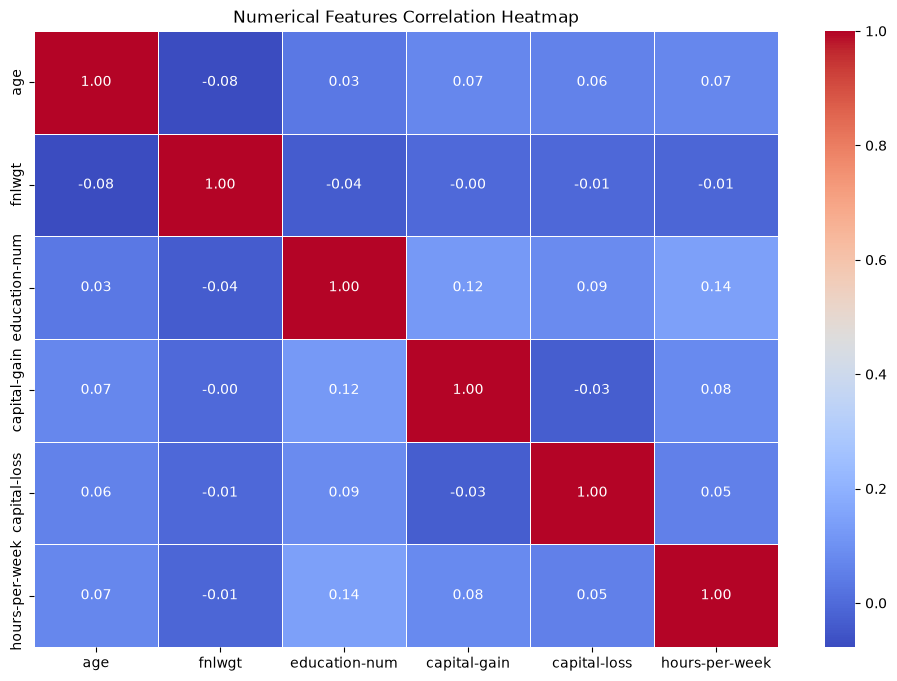

In [43]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap")
plt.show()

In [44]:
correlation_pairs = correlation_matrix.unstack()

high_correlations = correlation_pairs[
    (correlation_pairs.abs() > 0.70) &
    (correlation_pairs.abs() < 1.0)
]

print("Highly correlated feature pairs:")
print(high_correlations)

Highly correlated feature pairs:
Series([], dtype: float64)


In [45]:
from sklearn.feature_selection import mutual_info_classif

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Identify categorical encoded features
discrete_mask = np.array([
    name.startswith("cat__") for name in feature_names
])

# Calculate mutual information scores
mi_scores = mutual_info_classif(
    X_train_processed,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "MI_Score": mi_scores
})

feature_importance = feature_importance.sort_values(
    by="MI_Score",
    ascending=False
)

display(feature_importance.head(15))

,Feature,MI_Score
32,cat__marital-status_Married-civ-spouse,0.107539
51,cat__relationship_Husband,0.082842
3,num__capital-gain,0.079509
2,num__education-num,0.064722
0,num__age,0.064386
34,cat__marital-status_Never-married,0.063306
4,num__capital-loss,0.039855
5,num__hours-per-week,0.038737
1,num__fnlwgt,0.037306
54,cat__relationship_Own-child,0.036417


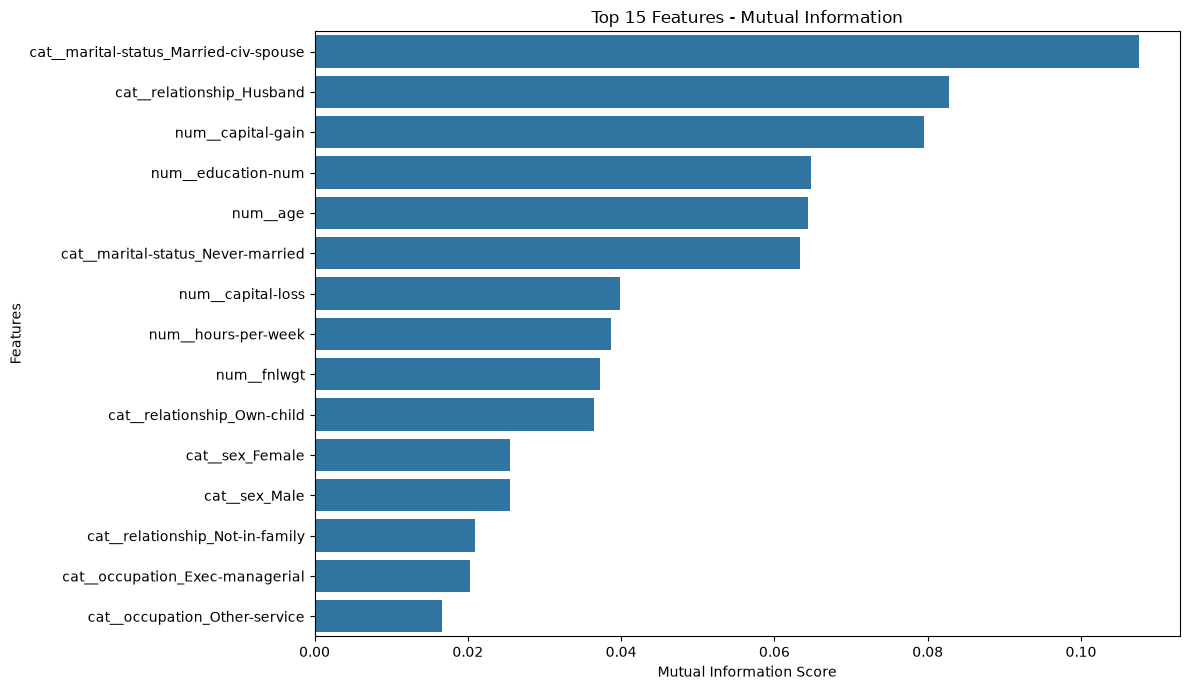

In [46]:
top_features = feature_importance.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="MI_Score",
    y="Feature"
)

plt.title("Top 15 Features - Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [47]:
best_feature = feature_importance.iloc[0]

print("Most Important Feature:", best_feature["Feature"])
print("Mutual Information Score:", best_feature["MI_Score"])

Most Important Feature: cat__marital-status_Married-civ-spouse
Mutual Information Score: 0.10753898119999579


In [48]:
from sklearn.ensemble import RandomForestClassifier

from sklearn.pipeline import Pipeline

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Complete ML Pipeline created successfully!")

Complete ML Pipeline created successfully!


In [49]:
model_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model_pipeline.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.8601699252738254

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7431
        >50K       0.74      0.64      0.69      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.78      0.80      9769
weighted avg       0.86      0.86      0.86      9769



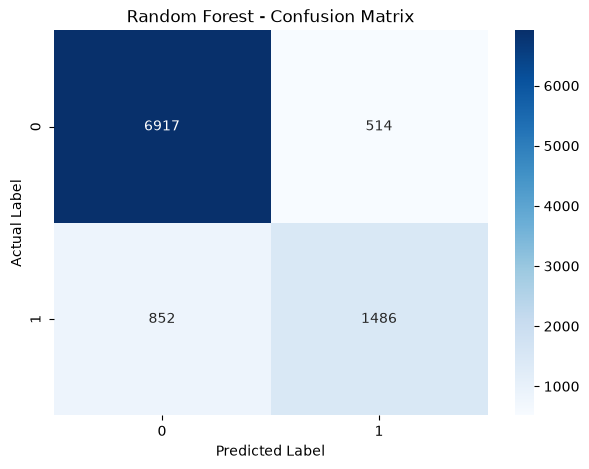

In [51]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [52]:
import joblib

joblib.dump(
    model_pipeline,
    "feature_engineering_pipeline.pkl"
)

print("Pipeline saved successfully!")

Pipeline saved successfully!


## Conclusion

In this project, a complete machine learning preprocessing pipeline was developed using Scikit-Learn. The Adult Census Income dataset was used to demonstrate data cleaning, missing value imputation, numerical feature scaling, categorical feature encoding, and correlation analysis.

A ColumnTransformer was implemented to apply different preprocessing techniques to numerical and categorical features. Train-test splitting was performed before preprocessing to prevent data leakage.

Mutual Information was used to identify important features, and a Random Forest Classifier was trained to predict income categories. The model was evaluated using accuracy, classification report, and confusion matrix.

The final pipeline was saved for future reuse. This project demonstrates a structured, reusable, and leak-free machine learning workflow.